# AAPL event-level descriptive analysis — December 30, 2019

**Research question:** How do new displayed-order messages, cancellations, and book executions vary during this trading day?

We also ask whether buy/sell **new-order submissions** have different size distributions, and whether different message counts move together within the same minute.

This notebook covers **A. Data collection and processing** and **B. Descriptive analysis and visualization**. It uses the full retained AAPL event history; it does not reconstruct a book or estimate causal effects. Spread, mid-price, depth, order lifetimes, and aggressor classification are deferred until replay is implemented.

**Run:** from the repository root, run `uv sync --locked --group analysis`, then `uv run --group analysis jupyter lab`. Open this notebook and select the project's `.venv` Python kernel. Run all cells in order. The saved outputs below were generated from the bundled reference file.

## Contents
1. [Source, scope, and observation units](#source-scope)
2. [Load and audit the data](#load-audit)
3. [Construct informative variables](#variables)
4. [Describe event activity](#activity)
5. [Study order quantities and submission sides](#quantities-sides)
6. [Explore relationships](#relationships)
7. [Findings, limitations, and next steps](#findings)

**Editing interpretations:** these are ordinary Markdown cells describing the bundled reference dataset. Review and update their numbers and conclusions if you change the input or calculations.

<a id="source-scope"></a>

## 1. Source, scope, and observation units

- **Source:** Nasdaq TotalView-ITCH 5.0 BinaryFILE archive `12302019.NASDAQ_ITCH50.gz`, decoded by this repository's converter. The compressed raw file contains multiple stocks; this Parquet contains selected AAPL messages and global session markers.
- **Ticker/date:** AAPL, December 30, 2019. Times use **America/New_York**.
- **Preparation already done:** binary framing, strict decoding, selected-order replay validation, session checks, Parquet writing. The shared field contract is in [common/SCHEMA.md](../common/SCHEMA.md); [the conversion guide](../book-reconstruction/README.md) describes its checks and limits.
- **Coverage limits:** one stock, one day, one venue's displayed-book messages and reported trades. Hidden orders are not reconstructed. A successful validation cannot prove that the source omitted no well-formed messages.
- **Multiple-source criterion:** this notebook uses **one market-data source**. The directory, event log, and conversion report are not independent sources. Combining another ticker/date or a justified external dataset is future work, not something claimed here.

**Two observation units:** (1) one recorded event, for message counts and quantities; (2) one fixed minute, for comparable rates and relationships. A message is not necessarily a unique trade or an independent trader decision. We never interpret a message-count percentage as the probability an individual order gets cancelled.

An `A/F` message adds a displayed order; `X` withdraws a supplied number of shares; `D` deletes the remaining order without supplying its size; `U` replaces an old ID with a new one. `E/C` refer to book executions. `P` and `Q` are separate trade/cross reports and do not update the displayed book. See the [Nasdaq specification, sections 1.3–1.5](https://www.nasdaqtrader.com/content/technicalsupport/specifications/dataproducts/NQTVITCHspecification.pdf).

In [1]:
import json
import sys
from datetime import date
from importlib.metadata import version
from pathlib import Path

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

from analysis.data import file_sha256, load_market_data
from common.enums import Ticker
from common.schema import BODY_FIELDS

%matplotlib inline

# Find the checkout whether Jupyter starts in the root or in analysis/.
ROOT = next(
    candidate
    for candidate in (Path.cwd(), *Path.cwd().parents)
    if (candidate / "pyproject.toml").is_file() and (candidate / "common/schema.py").is_file()
)
OUTPUT = ROOT / "analysis/outputs"
FIGURES = OUTPUT / "figures"
FIGURES.mkdir(parents=True, exist_ok=True)
plt.rcParams.update(
    {
        "figure.dpi": 110,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": True,
        "grid.alpha": 0.2,
        "font.size": 10,
    }
)
pd.set_option("display.max_columns", 12)
pd.set_option("display.max_rows", 40)
print("Python:", sys.version.split()[0])
print({name: version(name) for name in ("pyarrow", "pandas", "numpy", "matplotlib")})

Python: 3.10.12
{'pyarrow': '23.0.1', 'pandas': '2.3.3', 'numpy': '2.2.6', 'matplotlib': '3.10.9'}


<a id="load-audit"></a>

## 2. Load and audit the data

The input is an **explicit choice**, not a fallback. The reference checksum below identifies the Parquet bytes, not the compressed source. For another converted file, intentionally change `DATA_PATH`, date/ticker, and checksum settings before running; do not suppress a checksum failure by accident.

`load_market_data` returns a named **MarketData** object containing an Arrow event table and session metadata. It checks the shared column types, metadata, ordering, and the required/null fields of each message type. It raises on inconsistencies; it does not sort, remove, or impute events. The conversion stage remains responsible for full order-lifecycle validation.

In [ ]:
# these are the default values 
DATA_PATH = ROOT / "data/default/AAPL_2019-12-30.parquet"
EXPECTED_DATE = date(2019, 12, 30)
EXPECTED_SHA256 = "2c93c9d258a079fcc2c19f2d3eba04609d1782b58260621631a277a7c0b20279"

market = load_market_data(
    DATA_PATH,
    expected_ticker=Ticker.AAPL,
    expected_date=EXPECTED_DATE,
    expected_sha256=EXPECTED_SHA256,
)
input_hash = file_sha256(DATA_PATH)
identity = pd.Series(
    {
        "ticker": market.ticker.value,
        "session_date": market.session_date.isoformat(),
        "timezone": market.timezone,
        "schema_version": market.schema_version,
        "rows": market.events.num_rows,
        "columns": market.events.num_columns,
        "file_MB": round(DATA_PATH.stat().st_size / 1_000_000, 2),
        "sha256": input_hash,
    },
    name="Selected dataset",
)
display(identity.to_frame())

,Selected dataset
ticker,AAPL
session_date,2019-12-30
timezone,America/New_York
schema_version,1.0.0
rows,1519367
columns,34
file_MB,23.26
sha256,2c93c9d258a079fcc2c19f2d3eba04609d1782b5826062...


### Missing values are conditional on message type

An execution `E` supplies no price or side; a deletion `D` supplies no quantity. These nulls are **structural absence**, not missing observations that should be filled with zero. Similarly, a `P` side value is a legacy code and cannot be used as an aggressor or resting-side label.

The audit below covers all stored columns. The applicability matrix illustrates the contract for core fields. No global `dropna()`, zero imputation, forward-filling prices, winsorization, or deduplication is applied. Multiple events can have the same timestamp; sequence distinguishes their order. Gaps in source sequence are expected after filtering other stocks.

In [3]:
missing_audit = pd.DataFrame(
    [
        {
            "column": field.name,
            "Arrow type": str(field.type),
            "null_count": market.events[field.name].null_count,
            "null_pct": 100 * market.events[field.name].null_count / market.events.num_rows,
        }
        for field in market.events.schema
    ]
)
display(missing_audit)
core_fields = ["order_id", "new_order_id", "side", "shares", "price_units", "match_id"]
applicability = pd.DataFrame(
    {
        kind: {field: "required" if field in fields else "not supplied" for field in core_fields}
        for kind, fields in BODY_FIELDS.items()
    }
).T
applicability.index.name = "message_type"
display(applicability)

,column,Arrow type,null_count,null_pct
0,sequence,uint64,0,0.000000
1,timestamp_ns,uint64,0,0.000000
2,message_type,string,0,0.000000
3,stock_locate,uint16,0,0.000000
4,tracking_number,uint16,0,0.000000
5,order_id,uint64,10,0.000658
6,new_order_id,uint64,1422399,93.617868
7,side,string,813445,53.538414
8,shares,uint64,654465,43.074846
9,stock,string,813441,53.538151


,order_id,new_order_id,side,shares,price_units,match_id
message_type,,,,,,
S,not supplied,not supplied,not supplied,not supplied,not supplied,not supplied
R,not supplied,not supplied,not supplied,not supplied,not supplied,not supplied
H,not supplied,not supplied,not supplied,not supplied,not supplied,not supplied
h,not supplied,not supplied,not supplied,not supplied,not supplied,not supplied
A,required,not supplied,required,required,required,not supplied
F,required,not supplied,required,required,required,not supplied
E,required,not supplied,not supplied,required,not supplied,required
C,required,not supplied,not supplied,required,required,required
X,required,not supplied,not supplied,required,not supplied,not supplied


In [4]:
# Only these columns are needed for this analysis. Arrow-backed pandas columns
# preserve nullable unsigned IDs instead of converting them into floating point.
columns = [
    "sequence",
    "timestamp_ns",
    "message_type",
    "order_id",
    "new_order_id",
    "side",
    "shares",
    "price_units",
    "match_id",
    "printable",
    "cross_type",
    "event_code",
    "round_lot_size",
]
events = market.events.select(columns).to_pandas(types_mapper=pd.ArrowDtype)
events["message_type"] = events["message_type"].astype("category")
local_midnight = pd.Timestamp(market.session_date).tz_localize(market.timezone)
events["timestamp"] = local_midnight + pd.to_timedelta(
    events["timestamp_ns"].to_numpy(dtype="int64"), unit="ns"
)
assert len(events) == market.events.num_rows
assert events["sequence"].is_unique and events["sequence"].is_monotonic_increasing
assert events["timestamp"].is_monotonic_increasing
session_markers = events.loc[events["message_type"].eq("S"), ["event_code", "timestamp"]]
assert session_markers["event_code"].tolist() == list("OSQMEC")
display(session_markers.reset_index(drop=True))
display(
    events[["sequence", "timestamp", "message_type", "order_id", "shares", "price_units"]].head(8)
)
print("First retained timestamp:", events["timestamp"].min())
print("Last retained timestamp:", events["timestamp"].max())

,event_code,timestamp
0,O,2019-12-30 03:04:32.057543747-05:00
1,S,2019-12-30 04:00:00.000198145-05:00
2,Q,2019-12-30 09:30:00.000075566-05:00
3,M,2019-12-30 16:00:00.000071785-05:00
4,E,2019-12-30 20:00:00.000019686-05:00
5,C,2019-12-30 20:05:00.000040070-05:00


,sequence,timestamp,message_type,order_id,shares,price_units
0,1,2019-12-30 03:04:32.057543747-05:00,S,<NA>,<NA>,<NA>
1,14,2019-12-30 03:09:14.325932483-05:00,R,<NA>,<NA>,<NA>
2,8932,2019-12-30 03:09:14.653737350-05:00,H,<NA>,<NA>,<NA>
3,241733,2019-12-30 04:00:00.000198145-05:00,S,<NA>,<NA>,<NA>
4,241882,2019-12-30 04:00:00.007075802-05:00,A,11825,16,2999000
5,244463,2019-12-30 04:00:02.105991319-05:00,A,74473,73,2890000
6,247589,2019-12-30 04:00:09.160475329-05:00,A,104861,100,2498200
7,247990,2019-12-30 04:00:10.482288232-05:00,A,105925,80,2637000


First retained timestamp: 2019-12-30 03:04:32.057543747-05:00
Last retained timestamp: 2019-12-30 20:05:00.000040070-05:00


**Preparation decisions:** preserve input order and nanoseconds; keep IDs as nullable unsigned integers; localize using the exchange timezone rather than assuming UTC or a permanent EST offset. Dollar prices, when used, are integer `price_units / 10,000`. We do not average the price column across message types: an add's limit price and a trade's execution price answer different questions.

The source markers can occur microseconds after a clock boundary. For comparable minute bins we explicitly define **regular hours as [09:30, 16:00)** local time, after checking those clock minutes against the source's `Q/M` markers. The closing-cross print at/after 16:00 is outside this window. Opening-window book updates can include auction-related activity and should not be called purely continuous-trading executions.

In [5]:
market_open = local_midnight + pd.Timedelta(hours=9, minutes=30)
market_close = local_midnight + pd.Timedelta(hours=16)
marker_times = session_markers.set_index("event_code")["timestamp"]
assert marker_times.loc["Q"].floor("min") == market_open
assert marker_times.loc["M"].floor("min") == market_close
regular_index = pd.date_range(market_open, market_close, freq="min", inclusive="left")
assert len(regular_index) == 390
print("Regular-hours clock window:", market_open, "to", market_close, "(end excluded)")

Regular-hours clock window: 2019-12-30 09:30:00-05:00 to 2019-12-30 16:00:00-05:00 (end excluded)


<a id="variables"></a>

## 3. Construct informative variables

| Variable | Observation/unit | Definition and interpretation |
|---|---|---|
| `event_family` | Event/category | Groups original types without changing their semantics. |
| `minute` | Event/local clock minute | Left edge of a one-minute time bin. |
| `session_phase` | Event/category | Premarket, regular hours, or after-hours/cleanup, based on the declared clock window. |
| `submission_side` | New add only | Supplied side on `A/F`; never copied onto executions or inferred from `P`. |
| `below_round_lot` | New add only/boolean | Added shares smaller than the directory's round-lot size; not the same as every non-multiple size. |
| `interarrival_ms` | Regular-hours book event/ms | Time since the previous retained regular-hours book event; first gap stays null. |
| Message counts | Minute/messages | Counts separately for adds, executions, partial cancels, deletions, and replacements. |
| New-add / partial-cancel shares | Minute/shares | Sum supplied `A/F` or `X` quantities separately; not net book liquidity. |
| Cancel-message fraction | Minute/fraction | `(X count + D count) / all book-message count`; undefined if denominator is zero. |
| New-add share imbalance | Minute/fraction | `(buy A/F shares − sell A/F shares) / (buy + sell A/F shares)`; undefined without new adds. |

Cancellation **withdraws** displayed liquidity without a trade. It is not an aggressive execution. Replacement `U` quantities are new totals; we do not interpret them as a net addition. Cancel fractions and imbalance below are descriptive event-flow variables, not LPI/LCI definitions, trade directions, current book imbalance, or trader identities.

In [6]:
FAMILY = {
    "A": "Add",
    "F": "Add",
    "E": "Book execution",
    "C": "Book execution",
    "X": "Partial cancel",
    "D": "Delete",
    "U": "Replace",
    "P": "Hidden trade report",
    "Q": "Cross report",
    "B": "Trade break",
    "S": "Session marker",
    "R": "Directory",
    "H": "Trading status",
    "h": "Operational halt",
}
FLOW_FAMILIES = ["Add", "Delete", "Replace", "Book execution", "Partial cancel"]
COLORS = {
    "Add": "#2563eb",
    "Delete": "#ea580c",
    "Replace": "#9333ea",
    "Book execution": "#059669",
    "Partial cancel": "#b91c1c",
}
flow_mask = events["message_type"].isin(list("AFECXDU"))
add_mask = events["message_type"].isin(["A", "F"])
events["event_family"] = events["message_type"].astype("string").map(FAMILY).astype("category")
assert events["event_family"].notna().all()
events["minute"] = events["timestamp"].dt.floor("min")
events["session_phase"] = np.select(
    [events["timestamp"].lt(market_open), events["timestamp"].lt(market_close)],
    ["Premarket", "Regular hours"],
    default="After-hours / cleanup",
)
events["submission_side"] = events["side"].where(add_mask)
round_lot_values = events.loc[events["message_type"].eq("R"), "round_lot_size"].dropna()
assert len(round_lot_values) == 1 and round_lot_values.iloc[0] > 0
round_lot = int(round_lot_values.iloc[0])
events["below_round_lot"] = events["shares"].lt(round_lot).where(add_mask)
regular_mask = events["timestamp"].ge(market_open) & events["timestamp"].lt(market_close)
regular_flow = events.loc[regular_mask & flow_mask].copy()
regular_flow["interarrival_ms"] = regular_flow["timestamp"].diff().dt.total_seconds() * 1000
assert regular_flow["interarrival_ms"].dropna().ge(0).all()
print("Directory round-lot size:", round_lot, "shares")
print("Regular-hours book messages:", f"{len(regular_flow):,}")

Directory round-lot size: 100 shares
Regular-hours book messages: 1,477,242


In [7]:
# Reindexing a fixed grid includes minutes with zero observed messages.
# These zeros describe count bins; they do not replace missing event fields.
counts = (
    regular_flow.groupby(["minute", "event_family"], observed=True)
    .size()
    .unstack(fill_value=0)
    .reindex(index=regular_index, columns=FLOW_FAMILIES, fill_value=0)
)
counts.index.name = "minute"
assert int(counts.to_numpy().sum()) == len(regular_flow)
minute_features = counts.copy()
minute_features["all_book_messages"] = counts.sum(axis=1)


def shares_per_minute(codes: list[str]) -> pd.Series:
    """Return supplied quantities for selected types on the full regular-minute grid."""
    selected = events.loc[regular_mask & events["message_type"].isin(codes)]
    return (
        selected.groupby("minute")["shares"].sum(min_count=1).reindex(regular_index, fill_value=0)
    )


minute_features["new_add_shares"] = shares_per_minute(["A", "F"])
minute_features["partial_cancel_shares"] = shares_per_minute(["X"])
minute_features["cancel_message_fraction"] = (
    counts["Delete"] + counts["Partial cancel"]
) / minute_features["all_book_messages"].replace(0, np.nan)
assert len(minute_features) == 390
assert minute_features["cancel_message_fraction"].dropna().between(0, 1).all()
display(minute_features.head())

event_family,Add,Delete,Replace,Book execution,Partial cancel,all_book_messages,new_add_shares,partial_cancel_shares,cancel_message_fraction
minute,,,,,,,,,
2019-12-30 09:30:00-05:00,23806,1984,515,693,31,27029,2498652,5302,0.074550
2019-12-30 09:31:00-05:00,2883,2599,470,291,30,6273,269651,4000,0.419098
2019-12-30 09:32:00-05:00,3295,3116,691,261,23,7386,313906,4200,0.424993
2019-12-30 09:33:00-05:00,3246,3018,489,283,23,7059,291816,3600,0.430798
2019-12-30 09:34:00-05:00,4136,3944,688,365,21,9154,401827,3600,0.433144


**Why we do not calculate net liquidity yet:** a deletion's removed shares, a replacement's removed old quantity/side, and an execution's resting side require replay. Subtracting only `X` shares from `A/F` shares would ignore those changes and falsely label the result as net liquidity. This notebook deliberately keeps the supplied quantities separate.

<a id="activity"></a>

## 4. Describe event activity

### 4.1 Message mix

The table uses all retained rows for its full-day percentage, including supporting messages. The chart focuses on regular-hours market messages and uses a logarithmic count axis so rare types remain visible. Counts are messages, not turnover, executed share totals, or unique trades.

,full_day_messages,regular_messages,full_day_pct
message_type,,,
S,6,1,0.000395
R,1,0,0.000066
H,1,0,0.000066
h,0,0,0.000000
A,695972,691804,45.806708
F,2772,2714,0.182444
E,60203,59754,3.962374
C,340,321,0.022378
X,1467,1457,0.096553


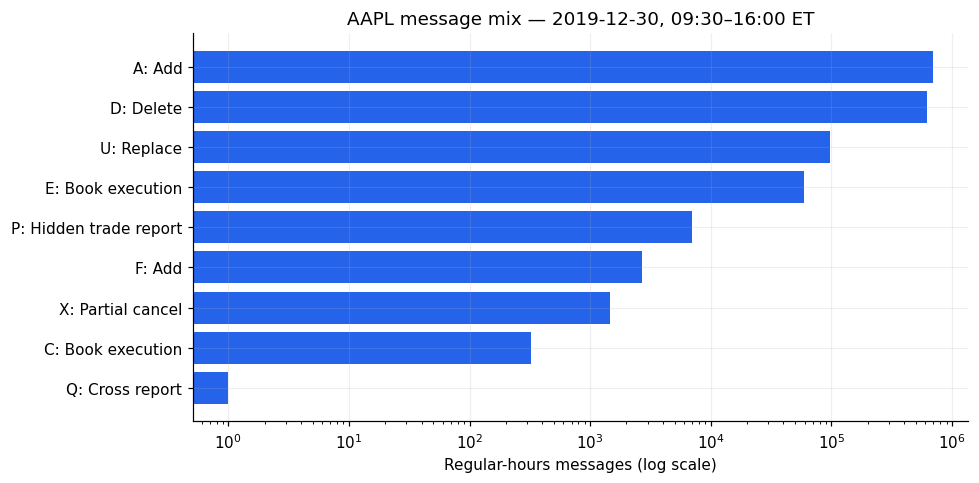

In [8]:
full_counts = (
    events["message_type"].value_counts().reindex(BODY_FIELDS, fill_value=0).astype("int64")
)
regular_counts = (
    events.loc[regular_mask, "message_type"]
    .value_counts()
    .reindex(BODY_FIELDS, fill_value=0)
    .astype("int64")
)
message_summary = pd.DataFrame(
    {"full_day_messages": full_counts, "regular_messages": regular_counts}
)
message_summary["full_day_pct"] = 100 * full_counts / len(events)
message_summary.index.name = "message_type"
display(message_summary)
market_codes = list("AFECXDUPQB")
chart_counts = regular_counts.reindex(market_codes)
chart_counts = chart_counts[chart_counts > 0].sort_values()
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.barh(
    [f"{kind}: {FAMILY[kind]}" for kind in chart_counts.index], chart_counts.values, color="#2563eb"
)
ax.set_xscale("log")
ax.set(
    xlabel="Regular-hours messages (log scale)",
    title="AAPL message mix — 2019-12-30, 09:30–16:00 ET",
)
fig.tight_layout()
fig.savefig(FIGURES / "01_message_mix.png", dpi=160, bbox_inches="tight")
plt.show()

In [9]:
add_delete_share = 100 * (counts["Add"].sum() + counts["Delete"].sum()) / counts.to_numpy().sum()

**Interpretation:** new adds and deletions together account for **89.3%** of regular-hours book messages under our definition. This describes message traffic, not the fraction of shares traded or the probability that an order is cancelled. `E/C`, `P`, and `Q` remain separate: adding every reported quantity would risk mixing book executions, non-displayed reports, and auction bulk prints.

### 4.2 Full-day context and session boundaries

Before restricting the analysis, inspect the full timeline. Activity outside regular hours can include session-related order removals. These should not automatically be interpreted as trading demand or included in a regular-hours rate comparison. Premarket and after-hours spans also have unequal durations.

,book_messages,first_event,last_event
session_phase,,,
Premarket,7091,2019-12-30 04:00:00.007075802-05:00,2019-12-30 09:29:59.994125551-05:00
Regular hours,1477242,2019-12-30 09:30:00.007441066-05:00,2019-12-30 15:59:59.991903763-05:00
After-hours / cleanup,27846,2019-12-30 16:00:00.000510319-05:00,2019-12-30 20:00:00.096734226-05:00


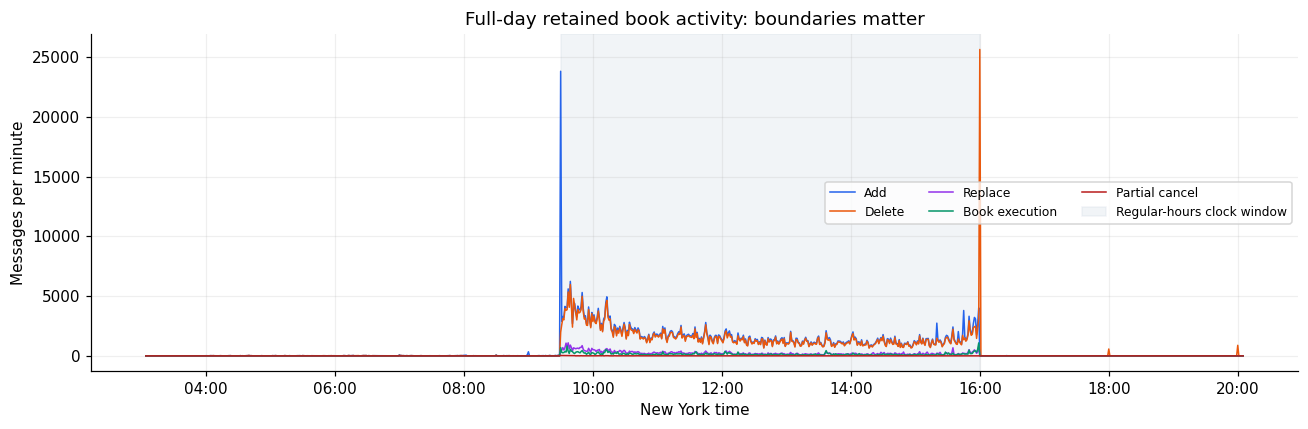

In [10]:
phase_summary = (
    events.loc[flow_mask]
    .groupby("session_phase", observed=True)
    .agg(
        book_messages=("sequence", "size"),
        first_event=("timestamp", "min"),
        last_event=("timestamp", "max"),
    )
    .reindex(["Premarket", "Regular hours", "After-hours / cleanup"])
)
display(phase_summary)
full_grid = pd.date_range(events["minute"].min(), events["minute"].max(), freq="min")
full_activity = (
    events.loc[flow_mask]
    .groupby(["minute", "event_family"], observed=True)
    .size()
    .unstack(fill_value=0)
    .reindex(index=full_grid, columns=FLOW_FAMILIES, fill_value=0)
)
fig, ax = plt.subplots(figsize=(12, 4))
for family in FLOW_FAMILIES:
    ax.plot(
        full_activity.index, full_activity[family], label=family, color=COLORS[family], linewidth=1
    )
ax.axvspan(
    market_open, market_close, color="#cbd5e1", alpha=0.25, label="Regular-hours clock window"
)
ax.xaxis.set_major_formatter(mdates.DateFormatter("%H:%M", tz=market.timezone))
ax.set(
    xlabel="New York time",
    ylabel="Messages per minute",
    title="Full-day retained book activity: boundaries matter",
)
ax.legend(ncol=3, fontsize=8)
fig.tight_layout()
fig.savefig(FIGURES / "02_full_day_activity.png", dpi=160, bbox_inches="tight")
plt.show()
peak_delete_minute = full_activity["Delete"].idxmax()

**Interpretation:** the largest deletion minute is **16:00 ET**, with **25,628 deletion messages**. Boundary activity may reflect session-related withdrawals, but timestamps alone do not identify the reason. We do not attribute this to informed traders or aggressive trades. Subsequent rate comparisons use the fixed regular-hours grid.

### 4.3 Regular-hours rates and equal-duration windows

Every row below represents **one minute**, including zero-count minutes. We summarize levels with mean, median, standard deviation, and tail quantiles. Three predeclared 30-minute windows make the opening/midday/closing comparison comparable in duration. These windows describe one realized day; they are not independent replicated trading days.

,count,mean,std,min,50%,90%,99%,max
event_family,,,,,,,,
Add,390.0,1780.815385,1429.994874,697.0,1461.5,3120.2,4978.93,23806.0
Delete,390.0,1600.597436,839.047611,645.0,1369.0,2705.2,4657.59,5967.0
Replace,390.0,248.612821,158.099921,53.0,202.5,458.8,800.93,1092.0
Book execution,390.0,154.038462,108.846492,45.0,124.0,274.8,545.10,1087.0
Partial cancel,390.0,3.735897,4.716050,0.0,2.0,8.0,23.55,31.0


,minutes,all_book_messages_per_min,Add_per_min,Delete_per_min,Replace_per_min,Book execution_per_min,Partial cancel_per_min
window,,,,,,,
Opening 30 min,30,9031.733333,4486.200000,3586.933333,621.233333,323.0,14.366667
Midday 30 min,30,2686.300000,1249.066667,1159.333333,165.700000,110.0,2.200000
Closing 30 min,30,4096.133333,1947.166667,1643.466667,267.566667,234.5,3.433333


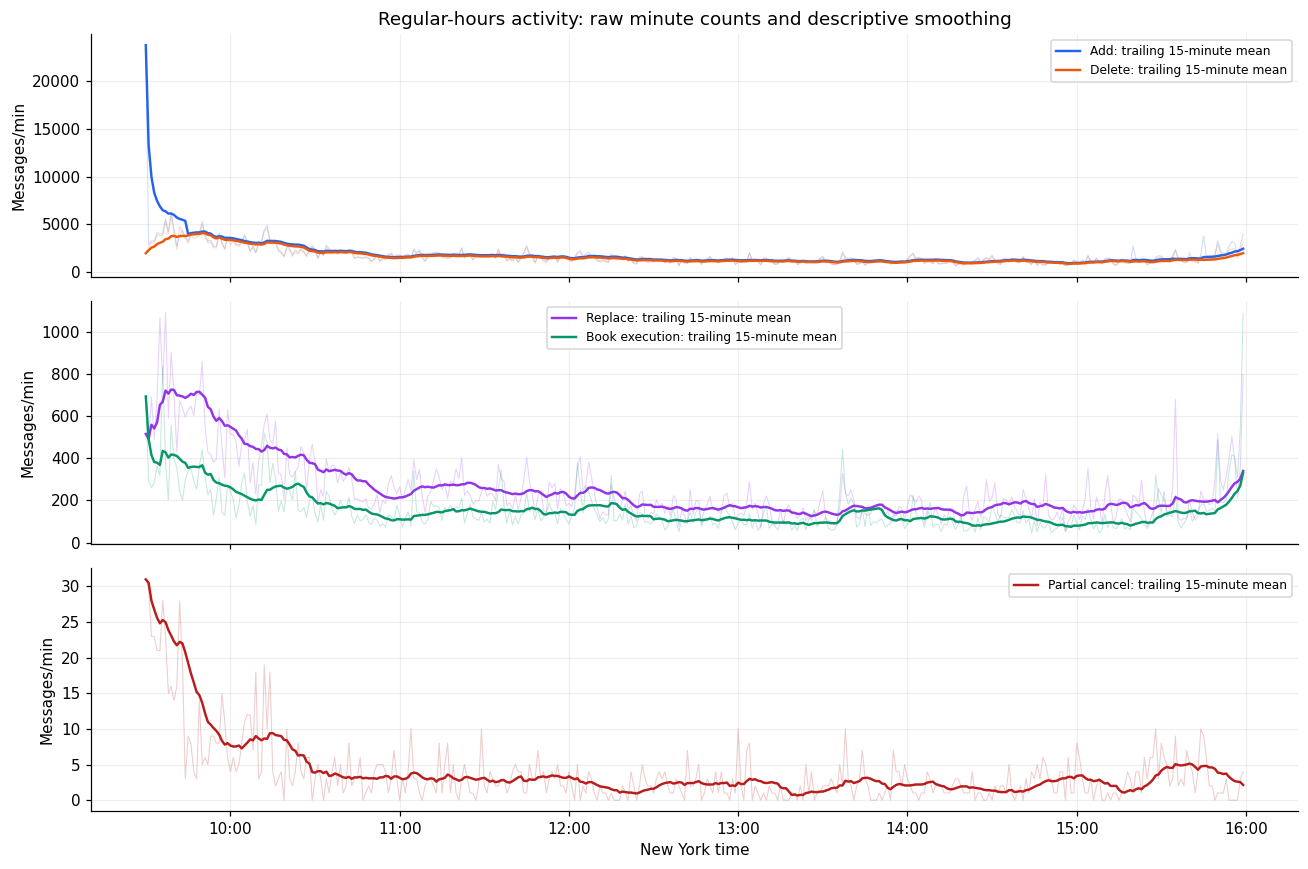

In [11]:
rate_summary = counts.describe(percentiles=[0.5, 0.9, 0.99]).T
rate_summary.index.name = "event_family"
display(rate_summary)
windows = [
    ("Opening 30 min", market_open, market_open + pd.Timedelta(minutes=30)),
    (
        "Midday 30 min",
        local_midnight + pd.Timedelta(hours=12, minutes=30),
        local_midnight + pd.Timedelta(hours=13),
    ),
    ("Closing 30 min", market_close - pd.Timedelta(minutes=30), market_close),
]
window_rows = []
for label, start, end in windows:
    block = minute_features.loc[(minute_features.index >= start) & (minute_features.index < end)]
    assert len(block) == 30
    window_rows.append(
        {
            "window": label,
            "minutes": len(block),
            "all_book_messages_per_min": block["all_book_messages"].mean(),
            **{f"{family}_per_min": block[family].mean() for family in FLOW_FAMILIES},
        }
    )
window_summary = pd.DataFrame(window_rows).set_index("window")
display(window_summary)

fig, axes = plt.subplots(3, 1, figsize=(12, 8), sharex=True)
for ax, families in zip(
    axes, [["Add", "Delete"], ["Replace", "Book execution"], ["Partial cancel"]]
):
    for family in families:
        ax.plot(counts.index, counts[family], color=COLORS[family], alpha=0.22, linewidth=0.7)
        ax.plot(
            counts.index,
            counts[family].rolling(15, min_periods=1).mean(),
            color=COLORS[family],
            label=f"{family}: trailing 15-minute mean",
            linewidth=1.6,
        )
    ax.set_ylabel("Messages/min")
    ax.legend(fontsize=8)
axes[0].set_title("Regular-hours activity: raw minute counts and descriptive smoothing")
axes[-1].xaxis.set_major_formatter(mdates.DateFormatter("%H:%M", tz=market.timezone))
axes[-1].set_xlabel("New York time")
fig.tight_layout()
fig.savefig(FIGURES / "03_regular_activity.png", dpi=160, bbox_inches="tight")
plt.show()

In [12]:
opening_rate = window_summary.loc["Opening 30 min", "all_book_messages_per_min"]
midday_rate = window_summary.loc["Midday 30 min", "all_book_messages_per_min"]
closing_rate = window_summary.loc["Closing 30 min", "all_book_messages_per_min"]

**Interpretation:** average book-message activity is **9,031.7/min** in the opening window, **2,686.3/min** at midday, and **4,096.1/min** in the closing window. The opening/midday ratio is **3.36**. These are measured window differences, not proof of a universal intraday shape. The opening window includes auction-related book updates. Thin raw curves expose spikes; the trailing mean smooths them and is not a forecast or a statistical confidence interval.

In [13]:
gaps = regular_flow["interarrival_ms"].dropna()
gap_summary = gaps.describe(percentiles=[0.5, 0.9, 0.99]).to_frame("milliseconds")
display(gap_summary)

,milliseconds
count,1.477241e+06
mean,1.584033e+01
std,5.158178e+01
min,0.000000e+00
50%,1.133570e-01
90%,4.545954e+01
99%,2.496645e+02
max,2.441006e+03


**Arrival timing:** **2.78%** of consecutive regular-hours book messages have equal timestamps. The median gap is **0.1134 ms**, while the mean is **15.8403 ms**. Ties are retained as distinct source events; the first gap is undefined and excluded only from this gap statistic. Bursty message timing does not by itself identify the number or identity of traders.

<a id="quantities-sides"></a>

## 5. Study order quantities and submission sides

### 5.1 Quantities within well-defined event categories

These are **message quantities**, not original order lifetimes or market-wide volume. Adds `A/F`, book executions `E/C`, and partial cancellations `X` are summarized separately. Deletion quantities are unavailable without replay, so they are not imputed. Replacements and trade/cross reports are excluded from this quantity comparison.

The distribution chart uses logarithmically spaced histogram bins and a log x-axis, with all positive sizes retained. Histogram bars are **counts in unequal-width bins**, not probability density. The empirical CDF provides an easier comparison of cumulative proportions.

,count,mean,std,min,50%,90%,99%,max
message quantity population,,,,,,,,
New add A/F,694518.0,99.613315,221.084402,1.0,100.0,100.0,400.0,52653.0
Book execution E/C,60075.0,83.702588,183.191375,1.0,80.0,110.0,500.0,11000.0
Partial cancel X,1457.0,120.671242,184.561854,1.0,100.0,200.0,400.0,6000.0


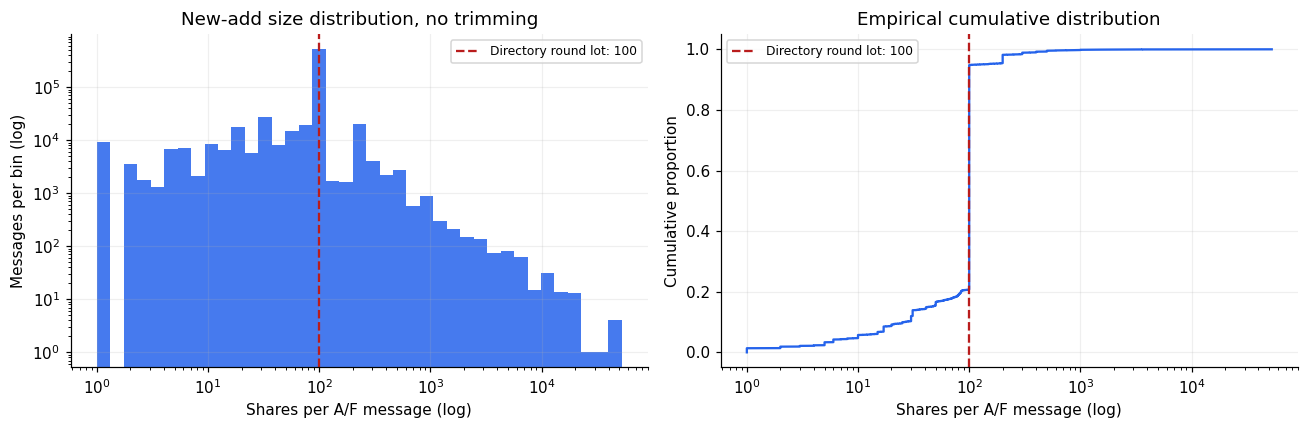

In [14]:
quantity_groups = {
    "New add A/F": events.loc[regular_mask & add_mask, "shares"].astype("int64"),
    "Book execution E/C": events.loc[
        regular_mask & events["message_type"].isin(["E", "C"]), "shares"
    ].astype("int64"),
    "Partial cancel X": events.loc[regular_mask & events["message_type"].eq("X"), "shares"].astype(
        "int64"
    ),
}
quantity_summary = pd.DataFrame(
    {
        name: series.describe(percentiles=[0.5, 0.9, 0.99])
        for name, series in quantity_groups.items()
    }
).T
quantity_summary.index.name = "message quantity population"
display(quantity_summary)
new_adds = events.loc[regular_mask & add_mask].copy()
add_sizes = new_adds["shares"].to_numpy(dtype="int64")
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(add_sizes, bins=np.geomspace(1, add_sizes.max() + 1, 40), color="#2563eb", alpha=0.85)
axes[0].set(
    xscale="log",
    yscale="log",
    xlabel="Shares per A/F message (log)",
    ylabel="Messages per bin (log)",
    title="New-add size distribution, no trimming",
)
sorted_sizes = np.sort(add_sizes)
axes[1].plot(sorted_sizes, np.arange(1, len(sorted_sizes) + 1) / len(sorted_sizes), color="#2563eb")
axes[1].set(
    xscale="log",
    xlabel="Shares per A/F message (log)",
    ylabel="Cumulative proportion",
    title="Empirical cumulative distribution",
)
for ax in axes:
    ax.axvline(
        round_lot, color="#b91c1c", linestyle="--", label=f"Directory round lot: {round_lot}"
    )
    ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(FIGURES / "04_order_sizes.png", dpi=160, bbox_inches="tight")
plt.show()

In [15]:
below_lot_pct = 100 * new_adds["below_round_lot"].mean()
median_add = float(np.median(add_sizes))
p99_add = float(np.quantile(add_sizes, 0.99))

**Interpretation:** the median new-add size is **100 shares**, the 99th percentile is **400**, and the maximum is **52,653**. **20.7%** of new-add messages are smaller than the directory's 100-share round lot. Large upper-tail observations coexist with many small submissions, so a single mean would hide heterogeneity. These are message-level sizes; we cannot infer trader types or investment motives from them.

### 5.2 Buy versus sell new-add flow

Side comparisons use **only `A/F`**. We compare supplied order counts, shares, and sizes. The five-minute plot aggregates new additions for readability. Its normalized difference measures new-add flow, not the active book's imbalance and not aggressive buying/selling. It omits replacement-side flow and all other changes that require replay.

,new_add_messages,new_add_shares,mean_size,median_size,below_round_lot_fraction
submission_side,,,,,
Buy,351789,34916732,99.254758,100.0,0.208548
Sell,342729,34266508,99.98135,100.0,0.205938


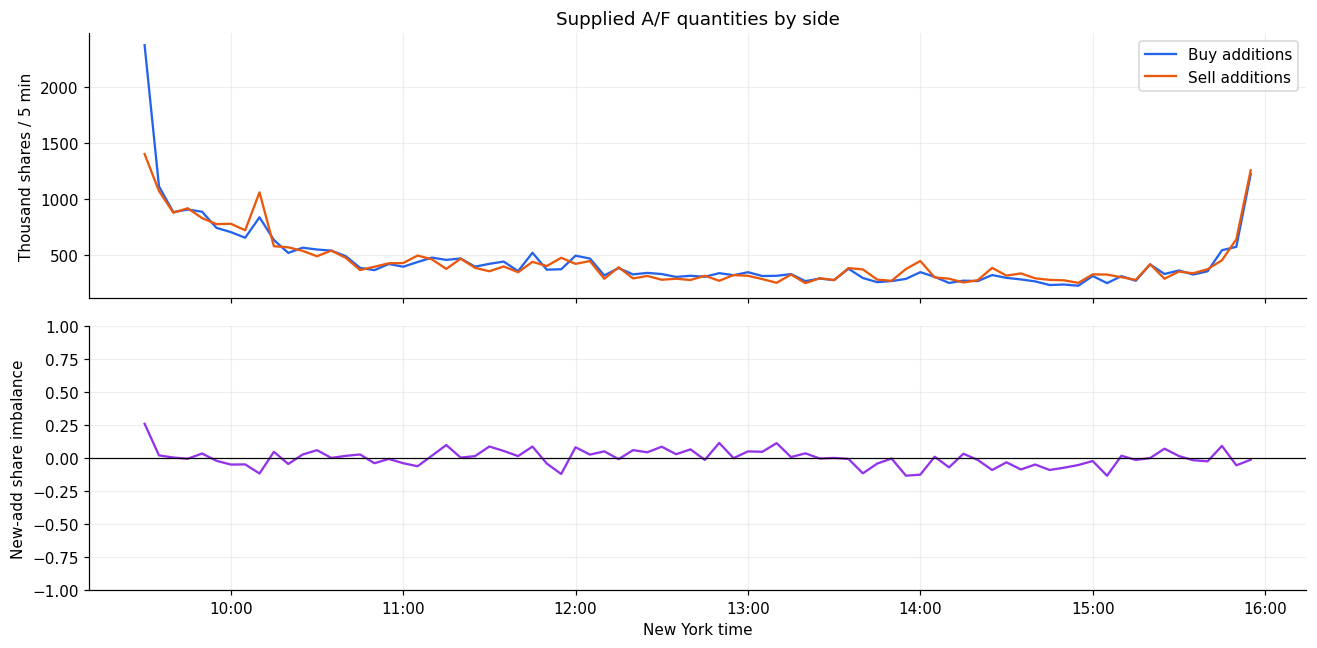

In [16]:
side_summary = (
    new_adds.groupby("submission_side", observed=True)
    .agg(
        new_add_messages=("sequence", "size"),
        new_add_shares=("shares", "sum"),
        mean_size=("shares", "mean"),
        median_size=("shares", "median"),
        below_round_lot_fraction=("below_round_lot", "mean"),
    )
    .rename(index={"B": "Buy", "S": "Sell"})
)
display(side_summary)
side_shares = (
    new_adds.groupby(["minute", "submission_side"], observed=True)["shares"]
    .sum()
    .unstack(fill_value=0)
    .reindex(index=regular_index, columns=["B", "S"], fill_value=0)
)
denominator = (side_shares["B"] + side_shares["S"]).astype("float64").replace(0, np.nan)
minute_features["new_add_share_imbalance"] = (
    side_shares["B"].astype("float64") - side_shares["S"].astype("float64")
) / denominator
assert minute_features["new_add_share_imbalance"].dropna().between(-1, 1).all()
five_minute_sides = side_shares.resample("5min", closed="left", label="left").sum()
five_denominator = (
    (five_minute_sides["B"] + five_minute_sides["S"]).astype("float64").replace(0, np.nan)
)
five_imbalance = (
    five_minute_sides["B"].astype("float64") - five_minute_sides["S"].astype("float64")
) / five_denominator
fig, axes = plt.subplots(2, 1, figsize=(12, 6), sharex=True)
axes[0].plot(
    five_minute_sides.index,
    five_minute_sides["B"].astype(float) / 1000,
    label="Buy additions",
    color="#2563eb",
)
axes[0].plot(
    five_minute_sides.index,
    five_minute_sides["S"].astype(float) / 1000,
    label="Sell additions",
    color="#ea580c",
)
axes[0].set(ylabel="Thousand shares / 5 min", title="Supplied A/F quantities by side")
axes[0].legend()
axes[1].plot(five_imbalance.index, five_imbalance, color="#9333ea")
axes[1].axhline(0, color="black", linewidth=0.8)
axes[1].set(ylabel="New-add share imbalance", ylim=(-1, 1), xlabel="New York time")
axes[1].xaxis.set_major_formatter(mdates.DateFormatter("%H:%M", tz=market.timezone))
fig.tight_layout()
fig.savefig(FIGURES / "05_submission_sides.png", dpi=160, bbox_inches="tight")
plt.show()

In [17]:
buy_share_fraction = float(
    side_summary.loc["Buy", "new_add_shares"] / side_summary["new_add_shares"].sum()
)

**Interpretation:** buy-side new additions account for **50.5%** of supplied A/F shares during regular hours. The time series can alternate between buy and sell dominance even if the daily totals are close. Neither the daily fraction nor the normalized flow measures the resting book, order aggressiveness, or future returns; orders may later be cancelled or replaced.

<a id="relationships"></a>

## 6. Explore relationships

Compare **same-minute message counts**, not mixed units or unrelated event prices. A scatter plot shows additions versus deletions; a Pearson correlation matrix compares the five count series. Shared intraday activity and serial dependence can generate strong relationships. We report no independence-based p-values and make no causal or forecasting claim.

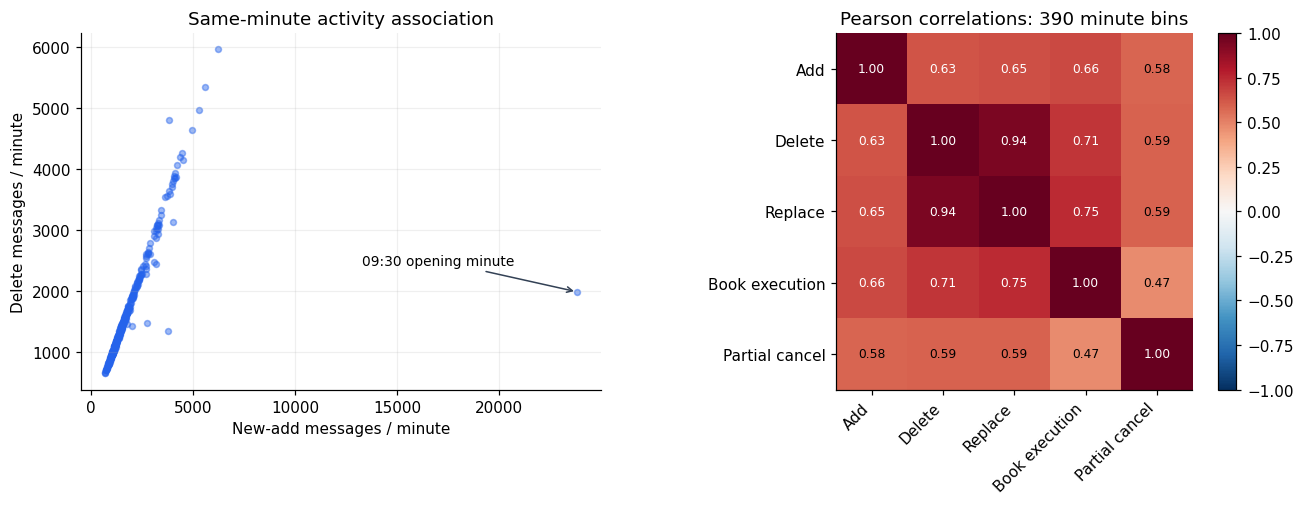

In [18]:
correlations = counts.corr(method="pearson")
fig, axes = plt.subplots(1, 2, figsize=(12, 4.7))
axes[0].scatter(counts["Add"], counts["Delete"], s=15, alpha=0.45, color="#2563eb")
axes[0].set(
    xlabel="New-add messages / minute",
    ylabel="Delete messages / minute",
    title="Same-minute activity association",
)
axes[0].annotate(
    "09:30 opening minute",
    xy=(counts.iloc[0]["Add"], counts.iloc[0]["Delete"]),
    xytext=(0.54, 0.35),
    textcoords="axes fraction",
    arrowprops={"arrowstyle": "->", "color": "#334155"},
    fontsize=9,
)
image = axes[1].imshow(correlations, cmap="RdBu_r", vmin=-1, vmax=1)
axes[1].set_xticks(range(len(FLOW_FAMILIES)), FLOW_FAMILIES, rotation=45, ha="right")
axes[1].set_yticks(range(len(FLOW_FAMILIES)), FLOW_FAMILIES)
axes[1].grid(False)
for i in range(len(FLOW_FAMILIES)):
    for j in range(len(FLOW_FAMILIES)):
        axes[1].text(
            j,
            i,
            f"{correlations.iloc[i, j]:.2f}",
            ha="center",
            va="center",
            fontsize=8,
            color="white" if abs(correlations.iloc[i, j]) > 0.6 else "black",
        )
axes[1].set_title("Pearson correlations: 390 minute bins")
fig.colorbar(image, ax=axes[1], fraction=0.046)
fig.tight_layout()
fig.savefig(FIGURES / "06_activity_relationships.png", dpi=160, bbox_inches="tight")
plt.show()
add_delete_corr = correlations.loc["Add", "Delete"]

**Interpretation:** the same-minute Pearson correlation between add and delete counts is **0.631**. This is consistent with activity co-movement, but does not show that a particular new order was later cancelled. A lifecycle analysis would need order-ID replay, and a broader conclusion would require additional days or stocks.

In [19]:
# Diagnostic sensitivity, not a cleaning rule: retain the opening minute in the
# primary analysis and show how strongly that one boundary bin affects Pearson r.
without_opening = counts.iloc[1:][["Add", "Delete"]].corr().loc["Add", "Delete"]
display(
    pd.DataFrame(
        {
            "minutes": [len(counts), len(counts) - 1],
            "add_delete_Pearson_r": [add_delete_corr, without_opening],
        },
        index=["Primary: all regular minutes", "Sensitivity: exclude 09:30 only"],
    )
)

,minutes,add_delete_Pearson_r
Primary: all regular minutes,390,0.630939
Sensitivity: exclude 09:30 only,389,0.983314


**Sensitivity interpretation:** without the opening minute, the correlation is **0.983**, compared with **0.631** in the full sample. The labelled opening minute has unusually many additions relative to deletions. This demonstrates Pearson correlation's sensitivity to a boundary observation. We retain it in the primary results: excluding it is a diagnostic, not an automatic outlier-removal rule. Common intraday trends can also explain the association.

<a id="findings"></a>

## 7. Findings, limitations, and next steps

### Data-preparation decisions and what remains unavailable

- We used a named, schema-checked reader and an explicit input identity; the source file is unchanged.
- Structural nulls were preserved. Zeroes were introduced only for empty **aggregate count/quantity bins**, never into event fields. Undefined ratios and the first interarrival gap stay missing.
- We retained all valid rows in the source and selected a clearly defined window for each comparison; full-day plots show the excluded context. No price outlier was silently removed.
- `A/F` submissions, `X` partial withdrawals, `D` deletions, `U` replacements, `E/C` book executions, and `P/Q` trade reports have different roles. Counts do not substitute for share-volume or order-lifecycle measures.
- We did not sum all execution/trade/cross reports into turnover. `C` non-printability and auction bulk prints require dedicated accounting; trade breaks would also require match-level handling.
- Data collection uses one existing source; the project has not yet added an API or independent second dataset. This limits the multiple-source component of the rubric.

### Next analytical layer

Replay order IDs to recover deletion quantities, replacement effects, resting sides, and live book state. Then sample book states on a declared time grid to study spread, mid-price, depth, and book imbalance. Define LPI/LCI and aggressor classification explicitly before calculating them. For generalizable claims, extend to more dates/tickers, examine market-state changes, and distinguish association from causation.

In [20]:
# Export small, reproducible analysis products; do not duplicate the full event file.
message_summary.to_csv(OUTPUT / "message_summary.csv")
minute_features.to_csv(OUTPUT / "minute_features.csv")
quantity_summary.to_csv(OUTPUT / "quantity_summary.csv")
side_summary.to_csv(OUTPUT / "new_add_side_summary.csv")
window_summary.to_csv(OUTPUT / "window_summary.csv")
provenance = {
    "input_relative_path": str(DATA_PATH.relative_to(ROOT)),
    "parquet_sha256": input_hash,
    "ticker": market.ticker.value,
    "session_date": market.session_date.isoformat(),
    "schema_version": market.schema_version,
    "timezone": market.timezone,
    "rows": len(events),
    "regular_book_messages": len(regular_flow),
    "regular_minutes": len(regular_index),
    "window": "[09:30, 16:00) local; one-minute bins, including zero-count minutes",
    "packages": {name: version(name) for name in ("pyarrow", "pandas", "numpy", "matplotlib")},
}
_ = (OUTPUT / "provenance.json").write_text(json.dumps(provenance, indent=2) + "\n")

### Measured findings for this input
- **1,519,367** retained rows; **1,477,242** regular-hours book messages.
- Opening/midday activity ratio: **3.36** using equal 30-minute windows.
- New-add size: median **100**, 99th percentile **400** shares; **20.7%** are smaller than one round lot.
- Buy share of A/F added quantities: **50.5%**.
- Same-minute add/delete count correlation: **0.631**.

These are event-level descriptions of one AAPL session. They do not establish net liquidity, current book imbalance, trader motives, or a causal effect.

Small CSV tables, provenance, and six standalone PNG figures were written to `analysis/outputs/` (ignored by Git). All displayed figures and tables are also saved inside this notebook for review.

### References and reproducibility

- [Shared schema and message-field definitions](../common/SCHEMA.md).
- [Conversion pipeline and validation limits](../book-reconstruction/README.md).
- [Bundled dataset identity](../data/default/README.md).
- [Nasdaq TotalView-ITCH 5.0 specification](https://www.nasdaqtrader.com/content/technicalsupport/specifications/dataproducts/NQTVITCHspecification.pdf).
- [pandas nullable Arrow-backed dtypes](https://pandas.pydata.org/docs/reference/api/pandas.ArrowDtype.html) and [time resampling](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.resample.html).

The exact environment is recorded in `uv.lock`. Numeric outputs are recomputed from the selected data. Interpretation cells describe the reference results and should be reviewed when the data changes. Re-running from a fresh kernel regenerates outputs; no network access or raw-source download is part of notebook execution.